# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170337          # <-- your full roll number
NAME = "Adhya Razdan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170337   Name: Adhya Razdan   Fingerprint: 9EE6623A   Tickets: 14

Ticket_ID                                                                                   Ticket_Text
      T01                                                  The server has stopped syncing. Please help.
      T02                 Wifi has stopped syncing after the latest update. I have tried several times!
      T03                                                                 The LMS says 'Not Submitted'.
      T04                                The Matlab keeps disconnecting. The same problem occurs again.
      T05                           Printer failed to open since yesterday. I have tried several times!
      T06 I keep getting logged out of the Python when I use mobile hotspot. I don't know what changed.
      T07                                                          Email me at helpdesk@university.edu.
      T08                                                         The Wi-Fi works, b

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code

import pandas as pd
import string

# Process every generated ticket using the official pipeline
ticket_results = [
    process_ticket(text)
    for text in df["Ticket_Text"]
]

rows = []

for i, result in enumerate(ticket_results):
    rows.append({
        "Ticket_ID": df["Ticket_ID"].iloc[i],
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": list(dict.fromkeys(result["tokens"])),
        "Final Tokens": result["final"]
    })

# TOTAL row
rows.append({
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(r["sentences"]) for r in ticket_results),
    "Tokens": sum(len(r["tokens"]) for r in ticket_results),
    "Punctuation": sum(len(r["punct"]) for r in ticket_results),
    "Stopwords": sum(len(r["stops"]) for r in ticket_results),
    "Unique Tokens": len(set(
        token
        for r in ticket_results
        for token in r["tokens"]
    )),
    "Final Tokens": sum(len(r["final"]) for r in ticket_results)
})

q1_df = pd.DataFrame(rows)

with pd.option_context(
    "display.max_colwidth", 100,
    "display.max_columns", None,
    "display.width", 250
):
    display(q1_df)


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,"[The server has stopped syncing., Please help.]","[the, server, has, stopped, syncing, ., please, help, .]","[., .]","[the, has]","[the, server, has, stopped, syncing, ., please, help]","[server, stopped, syncing, please, help]"
1,T02,"[Wifi has stopped syncing after the latest update., I have tried several times!]","[wifi, has, stopped, syncing, after, the, latest, update, ., i, have, tried, several, times, !]","[., !]","[has, after, the, i, have]","[wifi, has, stopped, syncing, after, the, latest, update, ., i, have, tried, several, times, !]","[wifi, stopped, syncing, latest, update, tried, several, times]"
2,T03,[The LMS says 'Not Submitted'.],"[the, lms, says, 'not, submitted, ', .]","[', .]",[the],"[the, lms, says, 'not, submitted, ', .]","[lms, says, 'not, submitted]"
3,T04,"[The Matlab keeps disconnecting., The same problem occurs again.]","[the, matlab, keeps, disconnecting, ., the, same, problem, occurs, again, .]","[., .]","[the, the, same, again]","[the, matlab, keeps, disconnecting, ., same, problem, occurs, again]","[matlab, keeps, disconnecting, problem, occurs]"
4,T05,"[Printer failed to open since yesterday., I have tried several times!]","[printer, failed, to, open, since, yesterday, ., i, have, tried, several, times, !]","[., !]","[to, i, have]","[printer, failed, to, open, since, yesterday, ., i, have, tried, several, times, !]","[printer, failed, open, since, yesterday, tried, several, times]"
5,T06,"[I keep getting logged out of the Python when I use mobile hotspot., I don't know what changed.]","[i, keep, getting, logged, out, of, the, python, when, i, use, mobile, hotspot, ., i, do, n't, k...","[., .]","[i, out, of, the, when, i, i, do, what]","[i, keep, getting, logged, out, of, the, python, when, use, mobile, hotspot, ., do, n't, know, w...","[keep, getting, logged, python, use, mobile, hotspot, n't, know, changed]"
6,T07,[Email me at helpdesk@university.edu.],"[email, me, at, helpdesk, @, university.edu, .]","[@, .]","[me, at]","[email, me, at, helpdesk, @, university.edu, .]","[email, helpdesk, university.edu]"
7,T08,"[The Wi-Fi works, but the VPN doesn't.]","[the, wi-fi, works, ,, but, the, vpn, does, n't, .]","[,, .]","[the, but, the, does]","[the, wi-fi, works, ,, but, vpn, does, n't, .]","[wi-fi, works, vpn, n't]"
8,T09,"[Server keeps asking for login before the assignment deadline., This is urgent.]","[server, keeps, asking, for, login, before, the, assignment, deadline, ., this, is, urgent, .]","[., .]","[for, before, the, this, is]","[server, keeps, asking, for, login, before, the, assignment, deadline, ., this, is, urgent]","[server, keeps, asking, login, assignment, deadline, urgent]"
9,T10,[The file is 95.5% uploaded.],"[the, file, is, 95.5, %, uploaded, .]","[%, .]","[the, is]","[the, file, is, 95.5, %, uploaded, .]","[file, 95.5, uploaded]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

for i, text in enumerate(df["Ticket_Text"], start=1):
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    numbers = re.findall(r"\b\d+(?:\.\d+)*\b", text)
    capitalized = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
    vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)

    print(f"\nTicket T{i:02d}: {text}")
    print("Long words:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Words starting with a vowel:", vowel_words)

    # Replace emails, URLs, and phone numbers
    cleaned = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>", text
    )
    cleaned = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>", cleaned
    )
    cleaned = re.sub(
        r"(?<!\w)(?:\+91[- ]?)?(?:\d{5}[- ]\d{5}|\d{10}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)",
        "<PHONE>", cleaned
    )
    print("Anonymized:", cleaned)



Ticket T01: The server has stopped syncing. Please help.
Long words: ['server', 'stopped', 'syncing', 'Please']
Numbers: []
Capitalized words: ['The', 'Please']
Words starting with a vowel: []
Anonymized: The server has stopped syncing. Please help.

Ticket T02: Wifi has stopped syncing after the latest update. I have tried several times!
Long words: ['stopped', 'syncing', 'latest', 'update', 'several']
Numbers: []
Capitalized words: ['Wifi', 'I']
Words starting with a vowel: ['after', 'update', 'I']
Anonymized: Wifi has stopped syncing after the latest update. I have tried several times!

Ticket T03: The LMS says 'Not Submitted'.
Long words: ['Submitted']
Numbers: []
Capitalized words: ['The', 'LMS', 'Not', 'Submitted']
Words starting with a vowel: []
Anonymized: The LMS says 'Not Submitted'.

Ticket T04: The Matlab keeps disconnecting. The same problem occurs again.
Long words: ['Matlab', 'disconnecting', 'problem', 'occurs']
Numbers: []
Capitalized words: ['The', 'Matlab', 'The']
W

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r'https?://[^\s]+|www\.[^\s]+|'
    r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|'
    r'\+?\d{2,4}(?:[- ]\d{2,5}){1,3}|'
    r'\d+(?:\.\d+)+|'
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r'[A-Za-z]+(?:-[A-Za-z]+)+|'
    r'[A-Za-z]+|\d+'
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for i, text in enumerate(df["Ticket_Text"], start=1):
    print(f"\nTicket T{i:02d}")
    print("Custom:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

# Custom tokens from all tickets, if needed for comparison
custom_tokens = [
    token
    for text in df["Ticket_Text"]
    for token in my_tokenize(text)
]




Ticket T01
Custom: ['The', 'server', 'has', 'stopped', 'syncing', 'Please', 'help']
word_tokenize: ['The', 'server', 'has', 'stopped', 'syncing', '.', 'Please', 'help', '.']

Ticket T02
Custom: ['Wifi', 'has', 'stopped', 'syncing', 'after', 'the', 'latest', 'update', 'I', 'have', 'tried', 'several', 'times']
word_tokenize: ['Wifi', 'has', 'stopped', 'syncing', 'after', 'the', 'latest', 'update', '.', 'I', 'have', 'tried', 'several', 'times', '!']

Ticket T03
Custom: ['The', 'LMS', 'says', 'Not', 'Submitted']
word_tokenize: ['The', 'LMS', 'says', "'Not", 'Submitted', "'", '.']

Ticket T04
Custom: ['The', 'Matlab', 'keeps', 'disconnecting', 'The', 'same', 'problem', 'occurs', 'again']
word_tokenize: ['The', 'Matlab', 'keeps', 'disconnecting', '.', 'The', 'same', 'problem', 'occurs', 'again', '.']

Ticket T05
Custom: ['Printer', 'failed', 'to', 'open', 'since', 'yesterday', 'I', 'have', 'tried', 'several', 'times']
word_tokenize: ['Printer', 'failed', 'to', 'open', 'since', 'yesterday', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code

import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$", min=5)
lemmatizer = WordNetLemmatizer()

# Obtain S3 directly from the official preprocessing results
S3 = [
    token
    for result in ticket_results
    for token in result["final"]
]

# Unique final tokens, preserving order
unique_words = list(dict.fromkeys(S3))

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged_words = pos_tag(unique_words)
rows = []

for word, tag in tagged_words:
    results = {
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(
            word, pos=get_wordnet_pos(tag)
        )
    }

    if len(set(results.values())) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            **results
        })

q4_df = pd.DataFrame(
    rows,
    columns=["Word", "POS", "Porter", "Lancaster", "Regexp", "WordNet Lemma"]
)

print("Words with differing outputs:")
display(q4_df)


Words with differing outputs:


,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
0,server,NN,server,serv,server,server
1,stopped,VBD,stop,stop,stopped,stop
2,syncing,VBG,sync,synt,sync,sync
3,please,NN,pleas,pleas,please,please
4,wifi,VB,wifi,wif,wifi,wifi
5,latest,JJS,latest,latest,latest,late
6,update,JJ,updat,upd,update,update
7,tried,VBD,tri,tri,tried,try
8,several,JJ,sever,sev,several,several
9,times,NNS,time,tim,times,time


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Tokens,Unique Tokens,TTR
0,S1 (All tokens),165,94,0.5697
1,S2 (No punctuation),137,88,0.6423
2,S3 (Final tokens),79,61,0.7722
3,S4 (Porter stemmed),79,59,0.7468


TOP 10 WORDS IN S1


,Word,Frequency
0,.,22
1,the,15
2,i,7
3,is,5
4,please,3
5,wifi,3
6,this,3
7,urgent,3
8,server,2
9,has,2


TOP 10 WORDS IN S3


,Word,Frequency
0,please,3
1,wifi,3
2,urgent,3
3,server,2
4,stopped,2
5,syncing,2
6,help,2
7,tried,2
8,several,2
9,times,2


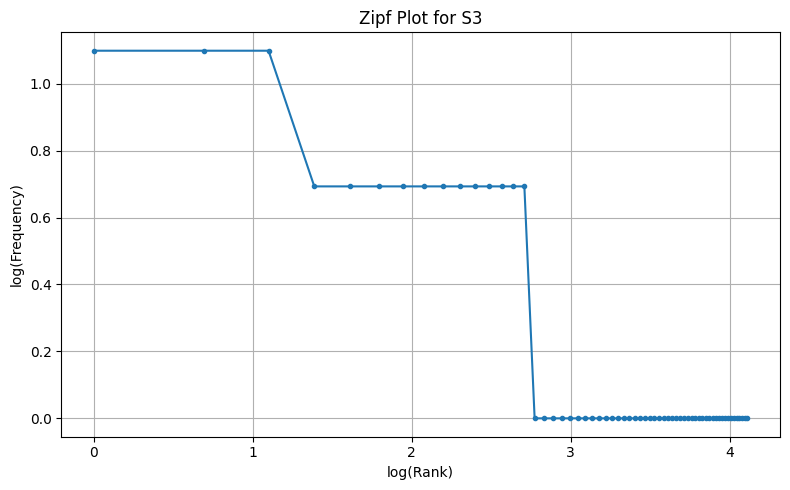

TOP 5 BIGRAMS IN S1
('.', 'i') : 5
('.', 'the') : 5
('.', 'please') : 3
('.', 'this') : 3
('this', 'is') : 3

TOP 5 BIGRAMS IN S3
('stopped', 'syncing') : 2
('please', 'help') : 2
('tried', 'several') : 2
('several', 'times') : 2
('since', 'yesterday') : 2


In [ ]:
# Your code

import math
import string
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.util import ngrams

# S1: All tokens, including punctuation
S1 = [
    token.lower()
    for text in df["Ticket_Text"]
    for token in word_tokenize(text)
]

# S2: Remove tokens consisting entirely of punctuation
S2 = [
    token for token in S1
    if not all(ch in string.punctuation for ch in token)
]

# S3: Final tokens from the official preprocessing pipeline
S3 = [
    token
    for result in ticket_results
    for token in result["final"]
]

# S4: Porter-stemmed S3
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

# Corpus statistics
corpora = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (Porter stemmed)": S4
}

stats = []

for name, corpus in corpora.items():
    stats.append({
        "Corpus": name,
        "Tokens": len(corpus),
        "Unique Tokens": len(set(corpus)),
        "TTR": round(len(set(corpus)) / len(corpus), 4)
        if corpus else 0
    })

print("CORPUS STATISTICS")
display(pd.DataFrame(stats))

# Top 10 words
print("TOP 10 WORDS IN S1")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("TOP 10 WORDS IN S3")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))

# Log(rank) vs log(frequency) for S3
frequencies = sorted(Counter(S3).values(), reverse=True)

if frequencies:
    ranks = range(1, len(frequencies) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(
        [math.log(r) for r in ranks],
        [math.log(f) for f in frequencies],
        marker="."
    )
    plt.xlabel("log(Rank)")
    plt.ylabel("log(Frequency)")
    plt.title("Zipf Plot for S3")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Top 5 bigrams
print("TOP 5 BIGRAMS IN S1")
for bigram, frequency in Counter(ngrams(S1, 2)).most_common(5):
    print(bigram, ":", frequency)

print("\nTOP 5 BIGRAMS IN S3")
for bigram, frequency in Counter(ngrams(S3, 2)).most_common(5):
    print(bigram, ":", frequency)


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*